# Waste Disposal Sites, Nonthaburi Province

**Data:** `data/raw/location.csv` — number of waste disposal sites each local government has, per year (data for 2563, 2564, 2566, 2567 — **2565 is missing**)

**Steps:** load → convert data types → fill gaps with the median → save `clean_location.csv` → charts: sites per year, share of local governments with/without their own disposal site, by district

# สถานที่กำจัดขยะมูลฝอย จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/location.csv` — จำนวนสถานที่กำจัดขยะ (แห่ง) ที่ อปท. แต่ละแห่งมี รายปี (มีข้อมูลปี 2563, 2564, 2566, 2567 — **ไม่มีปี 2565**)

**ขั้นตอน:** โหลด → แปลงชนิดข้อมูล → เติมค่าว่างด้วยมัธยฐาน → บันทึก `clean_location.csv` → กราฟ: จำนวนสถานที่รายปี, สัดส่วน อปท. ที่มี/ไม่มีสถานที่กำจัดของตัวเอง, รายอำเภอ

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/location.csv`

**โหลดข้อมูลดิบ** จาก `../data/raw/location.csv`

In [2]:
df = pd.read_csv('../data/raw/location.csv')
df

,ปี,จังหวัด,อำเภอ,อปท,สถานที่กำจัดขยะ(แห่ง)
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,2.0
1,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,1.0
2,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,1.0
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางรักพัฒนา,1.0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองพิมลราช,1.0
...,...,...,...,...,...
112,2567,นนทบุรี,ไทรน้อย,อบต.ราษฎร์นิยม,0.0
113,2567,นนทบุรี,บางบัวทอง,อบต.ละหาร,NaN
114,2567,นนทบุรี,บางบัวทอง,อบต.ลำโพ,0.0
115,2567,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,NaN


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

(The `isnull().sum()` line shows nothing because it is not the last statement in the cell — use the non-null counts from `info()` instead)

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

(บรรทัด `isnull().sum()` ไม่แสดงผลเพราะไม่ใช่คำสั่งสุดท้ายในเซลล์ — ดูจำนวนค่าไม่ว่างจาก `info()` แทน)

In [3]:
df.isnull().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ปี                     117 non-null    int64  
 1   จังหวัด                117 non-null    object 
 2   อำเภอ                  117 non-null    object 
 3   อปท                    117 non-null    object 
 4   สถานที่กำจัดขยะ(แห่ง)  72 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.7+ KB


**Convert the province / district / local government columns to `category`**

**แปลงคอลัมน์ จังหวัด / อำเภอ / อปท เป็น `category`**

In [4]:
for col in df.columns[1:4]:
    df[col] = df[col].astype('category')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   ปี                     117 non-null    int64   
 1   จังหวัด                117 non-null    category
 2   อำเภอ                  117 non-null    category
 3   อปท                    117 non-null    category
 4   สถานที่กำจัดขยะ(แห่ง)  72 non-null     float64 
dtypes: category(3), float64(1), int64(1)
memory usage: 4.0 KB


**Fill gaps in `สถานที่กำจัดขยะ(แห่ง)` (disposal sites) with the median** of the whole column

> Because most local governments have no disposal site of their own, the median is 0 — so empty rows are interpreted as "no disposal site"

**เติมค่าว่างของ `สถานที่กำจัดขยะ(แห่ง)` ด้วยค่ามัธยฐาน** ของทั้งคอลัมน์

> เนื่องจาก อปท. ส่วนใหญ่ไม่มีสถานที่กำจัดของตัวเอง ค่ามัธยฐานจึงเป็น 0 — แถวที่ว่างจึงถูกตีความว่า "ไม่มีสถานที่กำจัด"

In [5]:
df['สถานที่กำจัดขยะ(แห่ง)'] = df['สถานที่กำจัดขยะ(แห่ง)'].fillna(df['สถานที่กำจัดขยะ(แห่ง)'].median())
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   ปี                     117 non-null    int64   
 1   จังหวัด                117 non-null    category
 2   อำเภอ                  117 non-null    category
 3   อปท                    117 non-null    category
 4   สถานที่กำจัดขยะ(แห่ง)  117 non-null    float64 
dtypes: category(3), float64(1), int64(1)
memory usage: 4.0 KB


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [6]:
df.to_csv('../data/clean/clean_location.csv')

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [7]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [8]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(117, 5)


,ปี,จังหวัด,อำเภอ,อปท,สถานที่กำจัดขยะ(แห่ง)
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,2.0
1,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,1.0
2,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,1.0
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางรักพัฒนา,1.0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองพิมลราช,1.0


### 2.1 Bar chart: total disposal sites per year
**How to read it:** the total number of sites of every local government in each year — 2565 has no data in this dataset (shown as a gap, not 0)

### 2.1 กราฟแท่ง: จำนวนสถานที่กำจัดขยะรวมรายปี
**วิธีอ่าน:** ยอดรวมจำนวนสถานที่ของทุก อปท. ในแต่ละปี — ปี 2565 ไม่มีข้อมูลในชุดนี้ (แสดงเป็นช่องว่าง ไม่ใช่ 0)

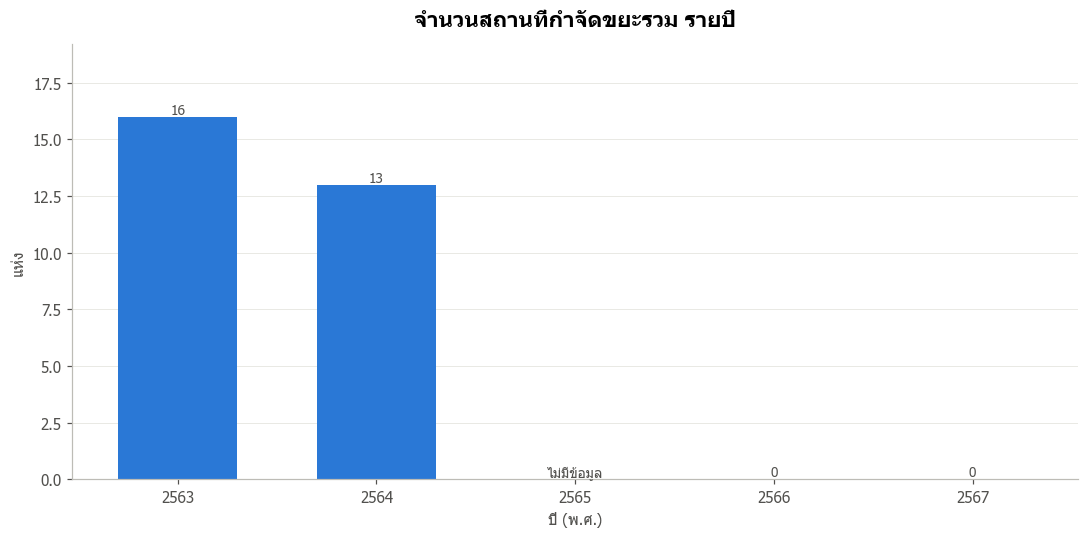

In [9]:
col = 'สถานที่กำจัดขยะ(แห่ง)'
all_years = range(viz['ปี'].min(), viz['ปี'].max() + 1)
yearly = viz.groupby('ปี')[col].sum().reindex(all_years)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(yearly.index.astype(str), yearly.fillna(0).values, color=PALETTE[0], width=0.6)
for b, v in zip(bars, yearly.values):
    ax.text(b.get_x() + b.get_width() / 2, 0 if np.isnan(v) else v,
            'ไม่มีข้อมูล' if np.isnan(v) else f'{v:,.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.margins(y=0.2); ax.grid(axis='x', visible=False)
ax.set_title('จำนวนสถานที่กำจัดขยะรวม รายปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('แห่ง')
plt.tight_layout(); plt.show()

### 2.2 Stacked bar chart: local governments with vs without their own disposal site
**How to read it:** blue = local governments with ≥ 1 disposal site, gray = none (they must send waste elsewhere, e.g. a central disposal center or a private operator). The number on each bar is the % of local governments with their own site

> ⚠️ **Important — the way data was collected changed:** in 2563–2564 the raw file contains **only local governments that have a disposal site** (12–15 rows, hence 100%), while 2566–2567 contain **every local government (45 rows)** but the values are 0 or empty (the 45 empty rows were filled with the median = 0). So all-zero values in later years **do not mean the disposal sites disappeared**; the data was most likely not filled in. Do not compare trends across these years directly

### 2.2 กราฟแท่งซ้อน: อปท. ที่มี vs ไม่มีสถานที่กำจัดขยะของตัวเอง
**วิธีอ่าน:** ส่วนสีน้ำเงิน = อปท. ที่มีสถานที่กำจัด ≥ 1 แห่ง, สีเทา = ไม่มี (ต้องส่งขยะไปกำจัดที่อื่น เช่น ศูนย์กำจัดรวมหรือเอกชน) ตัวเลขบนแท่งคือ % ของ อปท. ที่มีสถานที่เอง

> ⚠️ **ข้อสังเกตสำคัญ — รูปแบบการเก็บข้อมูลเปลี่ยนไป:** ปี 2563–2564 ไฟล์ดิบมี **เฉพาะ อปท. ที่มีสถานที่กำจัด** (12–15 แถว จึงได้ 100%) ส่วนปี 2566–2567 มี **ทุก อปท. (45 แถว)** แต่ค่าเป็น 0 หรือว่าง (ค่าว่าง 45 แถวถูกเติมด้วยมัธยฐาน = 0) ดังนั้นการที่ปีหลังเป็น 0 ทั้งหมด **ไม่ได้แปลว่าสถานที่กำจัดหายไป** แต่น่าจะเป็นเพราะไม่ได้กรอกข้อมูล — ไม่ควรนำมาเทียบแนวโน้มข้ามปีโดยตรง

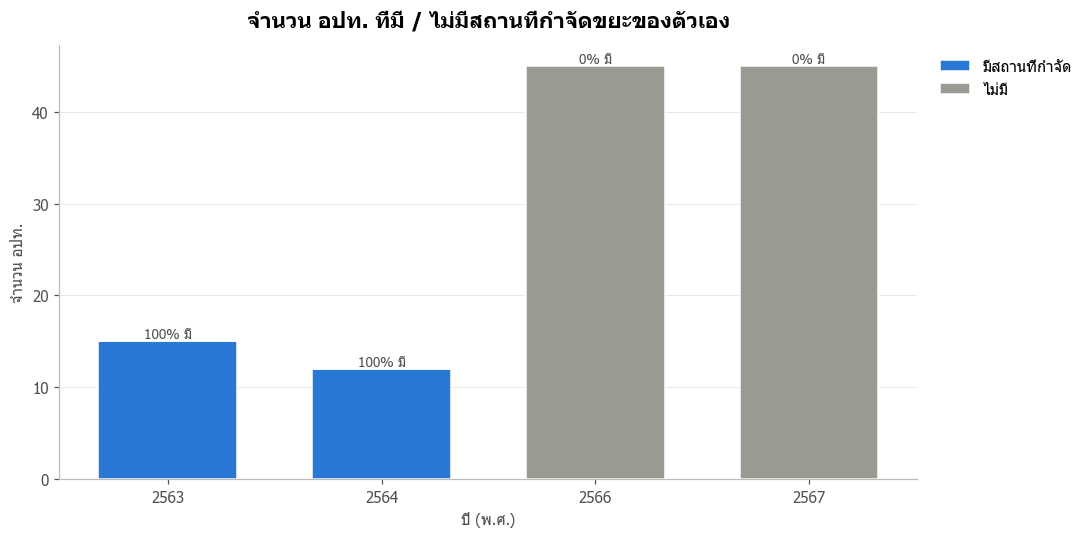

,มีสถานที่กำจัด,ไม่มี
ปี,,
2563,15,0
2564,12,0
2566,0,45
2567,0,45


In [10]:
col = 'สถานที่กำจัดขยะ(แห่ง)'
has = viz.assign(มี=viz[col] > 0).groupby('ปี')['มี'].agg(['sum', 'size'])
tbl = pd.DataFrame({'มีสถานที่กำจัด': has['sum'], 'ไม่มี': has['size'] - has['sum']})
fig, ax = plt.subplots(figsize=(10, 5))
totals = stacked_bar(ax, tbl, colors=[PALETTE[0], GRAY])
for i, (t, h) in enumerate(zip(totals, tbl.iloc[:, 0])):
    ax.text(i, t, f'{h / t * 100:.0f}% มี', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.set_title('จำนวน อปท. ที่มี / ไม่มีสถานที่กำจัดขยะของตัวเอง')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('จำนวน อปท.')
plt.tight_layout(); plt.show()
tbl

### 2.3 Heatmap: disposal sites by district × year
**How to read it:** rows = districts, columns = years, numbers = total sites of the local governments in that district, darker = more sites. The `ไม่มีข้อมูล` (no data) column is 2565, which is missing from the file (as noted above, the all-zero 2566–2567 values are probably data that was not filled in)

### 2.3 Heatmap: จำนวนสถานที่กำจัดขยะ รายอำเภอ × ปี
**วิธีอ่าน:** แถว = อำเภอ, คอลัมน์ = ปี, ตัวเลข = จำนวนสถานที่รวมของ อปท. ในอำเภอนั้น ช่องสีเข้ม = มีสถานที่กำจัดมาก ช่อง `ไม่มีข้อมูล` คือปี 2565 ที่ไม่มีในไฟล์ (ตามข้อสังเกตข้างบน ปี 2566–2567 ที่เป็น 0 ทั้งหมดน่าจะมาจากการไม่กรอกข้อมูล)

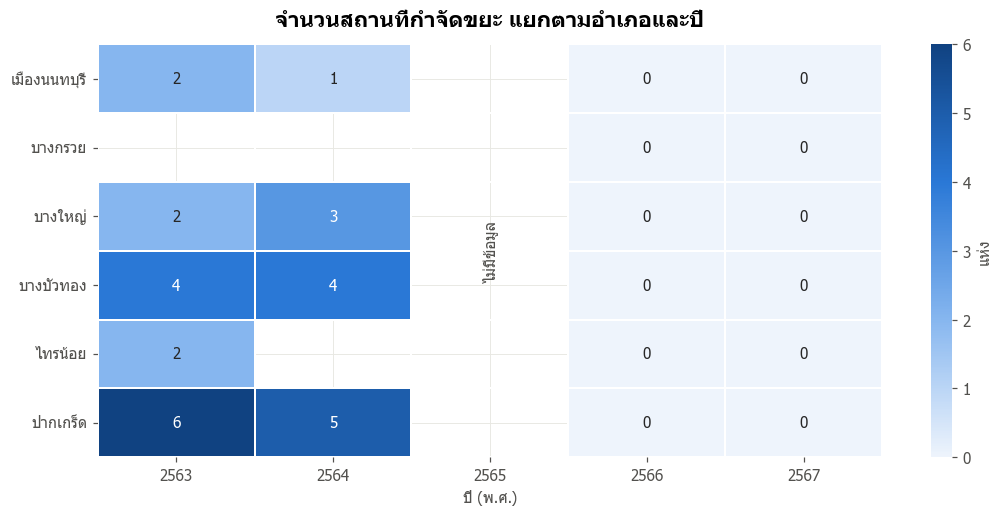

ปี,2563,2564,2565,2566,2567
อำเภอ,,,,,
เมืองนนทบุรี,2.0,1.0,NaN,0.0,0.0
บางกรวย,NaN,NaN,NaN,0.0,0.0
บางใหญ่,2.0,3.0,NaN,0.0,0.0
บางบัวทอง,4.0,4.0,NaN,0.0,0.0
ไทรน้อย,2.0,NaN,NaN,0.0,0.0
ปากเกร็ด,6.0,5.0,NaN,0.0,0.0


In [11]:
col = 'สถานที่กำจัดขยะ(แห่ง)'
all_years = list(range(viz['ปี'].min(), viz['ปี'].max() + 1))
heat = (viz.pivot_table(index='อำเภอ', columns='ปี', values=col, aggfunc='sum')
           .reindex(index=[d for d in DIST_ORDER if d in set(viz['อำเภอ'])], columns=all_years))
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(heat, annot=True, fmt='.0f', cmap=SEQ_CMAP, linewidths=1, linecolor='white',
            cbar_kws={'label': 'แห่ง'}, ax=ax)
for j, y in enumerate(all_years):                       # years with no data at all — ปีที่ไม่มีข้อมูลเลย
    if heat[y].isna().all():
        ax.text(j + 0.5, len(heat) / 2, 'ไม่มีข้อมูล', ha='center', va='center', rotation=90, fontsize=10, color=TEXT)
ax.set_title('จำนวนสถานที่กำจัดขยะ แยกตามอำเภอและปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()
heat

### 2.4 Table: local governments that have disposal sites
**What it does:** pivots so rows = local governments and columns = years, to see how many disposal sites each one has per year (`<NA>` = no data for that year) — a small table like this is easier to read than a chart when there are only a few rows

### 2.4 ตาราง: รายชื่อ อปท. ที่มีสถานที่กำจัดขยะ
**ทำอะไร:** pivot ให้แถว = อปท., คอลัมน์ = ปี เพื่อดูว่าแต่ละแห่งมีสถานที่กำจัดกี่แห่งในแต่ละปี (`<NA>` = ไม่มีข้อมูลปีนั้น) — ตารางเล็ก ๆ แบบนี้อ่านง่ายกว่ากราฟเมื่อมีข้อมูลไม่กี่แถว

In [12]:
col = 'สถานที่กำจัดขยะ(แห่ง)'
apts = viz.loc[viz[col] > 0, 'อปท'].unique()
(viz[viz['อปท'].isin(apts)]
   .pivot_table(index=['อำเภอ', 'อปท'], columns='ปี', values=col, aggfunc='sum')
   .astype('Int64'))   # <NA> = no data for that year — <NA> = ไม่มีข้อมูลปีนั้น

ปี                                   2563  2564  2566  2567
อำเภอ        อปท                                           
บางบัวทอง    อบต.บางรักใหญ่             1     1     0     0
             เทศบาลเมืองบางคูรัด        1     2     0     0
             เทศบาลเมืองบางรักพัฒนา     1     1     0     0
             เทศบาลเมืองพิมลราช         1  <NA>     0     0
บางใหญ่      อบต.บ้านใหม่            <NA>     1     0     0
             เทศบาลตำบลบางม่วง          1  <NA>     0     0
             เทศบาลตำบลบางใหญ่       <NA>     1     0     0
             เทศบาลตำบลเสาธงหิน         1     1  <NA>  <NA>
ปากเกร็ด     อบต.คลองข่อย               1     1     0     0
             อบต.ท่าอิฐ                 1     1     0     0
             อบต.บางตะไนย์              1     1     0     0
             อบต.เกาะเกร็ด              1     1     0     0
             เทศบาลนครปากเกร็ด          2     1     0     0
เมืองนนทบุรี อบต.บางไผ่                 1     1     0     0
             เทศบาลเมืองบางกร่าง        1  <NA>     0     0
ไทรน้อย      อบต.ราษฎร์นิยม             1  <NA>     0     0
             อบต.หนองเพรางาย            1  <NA>     0     0

---
## Key Findings

1. **There were 16 disposal sites in 2563 (2020) and 13 in 2564 (2021)** — Pak Kret (5–6 sites) and Bang Bua Thong (4 sites) have the most
2. **The 2566–2567 data cannot be used for comparison** — the file format changed (from only local governments with sites → every local government) and all values are 0/empty, and 2565 has no data
3. **Recommendation:** request the 2565–2567 data again from the source, or state in reports that the disposal-site data is only usable for 2563–2564

## สรุปข้อค้นพบ

1. **ปี 2563 มีสถานที่กำจัด 16 แห่ง, ปี 2564 มี 13 แห่ง** — ปากเกร็ด (5–6 แห่ง) และบางบัวทอง (4 แห่ง) มีมากที่สุด
2. **ข้อมูลปี 2566–2567 ใช้เปรียบเทียบไม่ได้** — รูปแบบไฟล์เปลี่ยน (จากเฉพาะ อปท. ที่มีสถานที่ → ทุก อปท.) และค่าทั้งหมดเป็น 0/ว่าง ส่วนปี 2565 ไม่มีข้อมูล
3. **ข้อเสนอ:** ควรขอข้อมูลปี 2565–2567 ใหม่จากแหล่งข้อมูล หรือระบุในรายงานว่าข้อมูลสถานที่กำจัดใช้ได้เฉพาะปี 2563–2564